In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv("StudentPerformanceFactors.csv")

df.head()


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [3]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


In [4]:
missing_cols = [
    'Teacher_Quality',
    'Parental_Education_Level',
    'Distance_from_Home'
]

for col in missing_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64


In [5]:
print("Duplicate Records:")
print(df.duplicated().sum())

Duplicate Records:
0


In [6]:
print("Numerical Variables:")
display(df.describe())

print("\nCategorical Variables:")
display(df.describe(include='object'))

Numerical Variables:


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000



Categorical Variables:


,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
count,6607,6607,6607,6607,6607,6607,6607,6607,6607,6607,6607,6607,6607
unique,3,3,2,3,2,3,3,2,3,2,3,3,2
top,Medium,Medium,Yes,Medium,Yes,Low,Medium,Public,Positive,No,High School,Near,Male
freq,3362,3319,3938,3351,6108,2672,4003,4598,2638,5912,3313,3951,3814


In [7]:
numeric_cols = df.select_dtypes(include=np.number).columns

print("Mean:")
print(df[numeric_cols].mean())

print("\nMedian:")
print(df[numeric_cols].median())

print("\nStandard Deviation:")
print(df[numeric_cols].std())

print("\nMinimum:")
print(df[numeric_cols].min())

print("\nMaximum:")
print(df[numeric_cols].max())

Mean:
Hours_Studied        19.975329
Attendance           79.977448
Sleep_Hours           7.029060
Previous_Scores      75.070531
Tutoring_Sessions     1.493719
Physical_Activity     2.967610
Exam_Score           67.235659
dtype: float64

Median:
Hours_Studied        20.0
Attendance           80.0
Sleep_Hours           7.0
Previous_Scores      75.0
Tutoring_Sessions     1.0
Physical_Activity     3.0
Exam_Score           67.0
dtype: float64

Standard Deviation:
Hours_Studied         5.990594
Attendance           11.547475
Sleep_Hours           1.468120
Previous_Scores      14.399784
Tutoring_Sessions     1.230570
Physical_Activity     1.031231
Exam_Score            3.890456
dtype: float64

Minimum:
Hours_Studied         1
Attendance           60
Sleep_Hours           4
Previous_Scores      50
Tutoring_Sessions     0
Physical_Activity     0
Exam_Score           55
dtype: int64

Maximum:
Hours_Studied         44
Attendance           100
Sleep_Hours           10
Previous_Scores      100
Tu

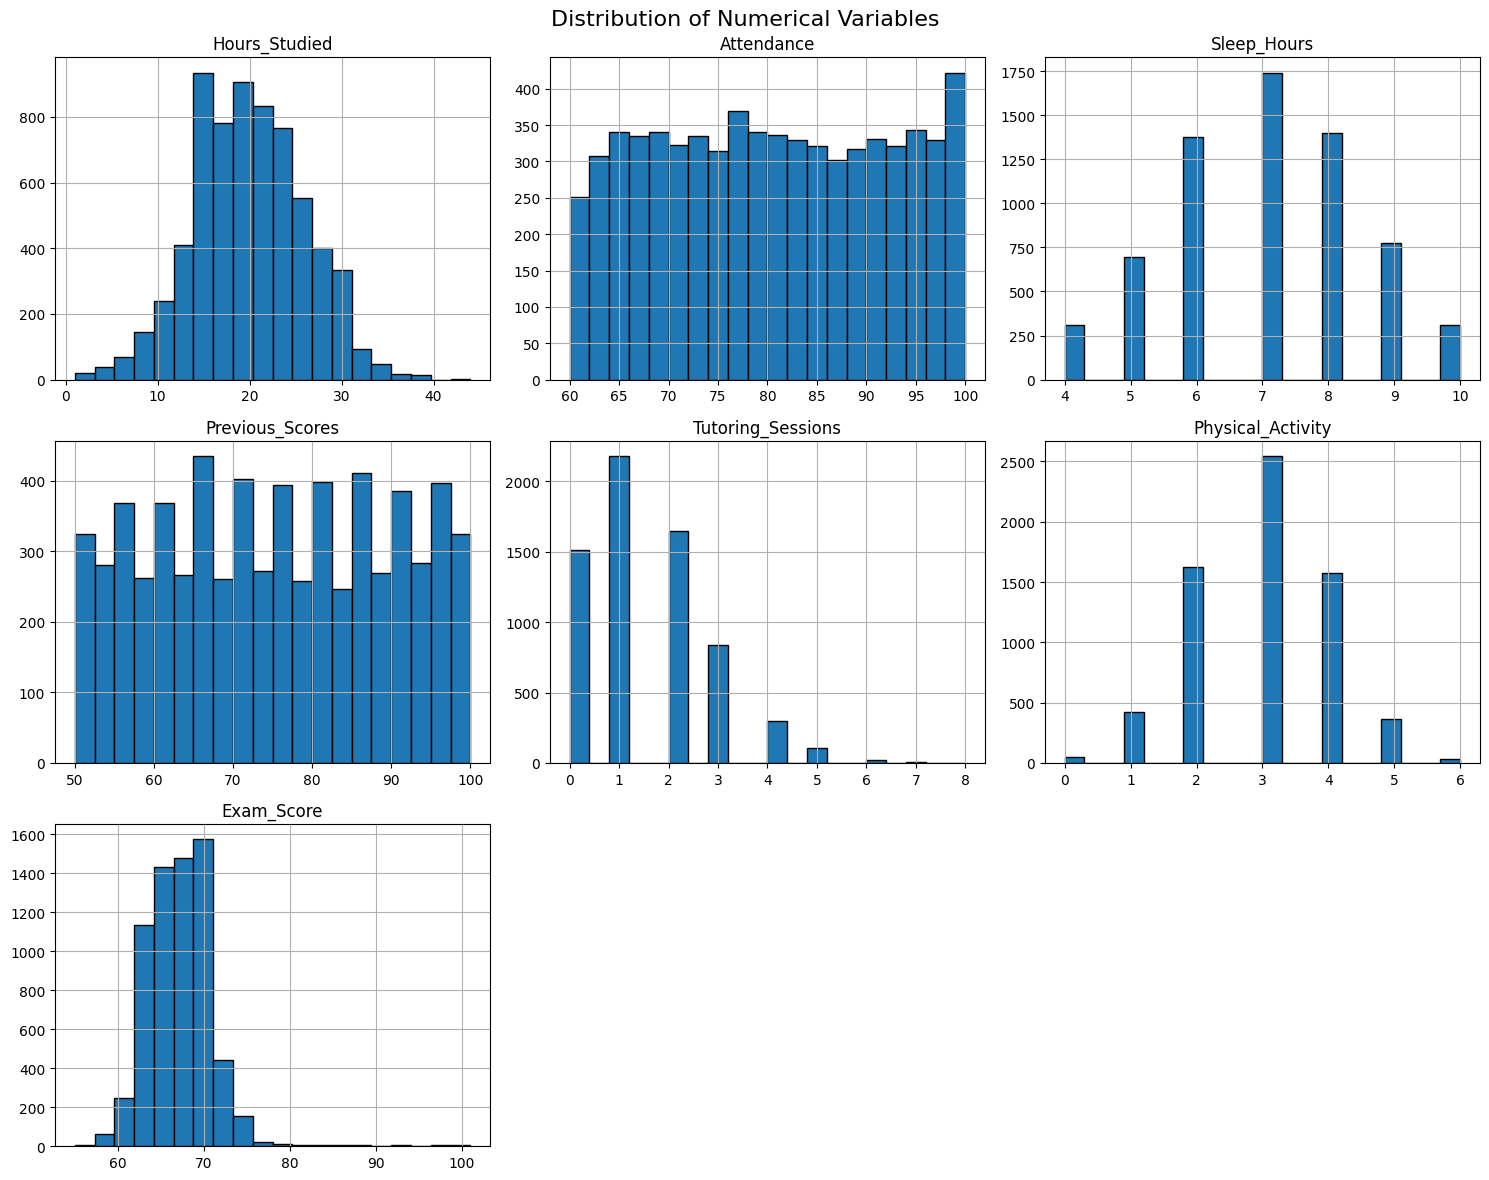

In [8]:
numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols].hist(
    figsize=(15, 12),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Distribution of Numerical Variables", fontsize=16)
plt.tight_layout()
plt.show()

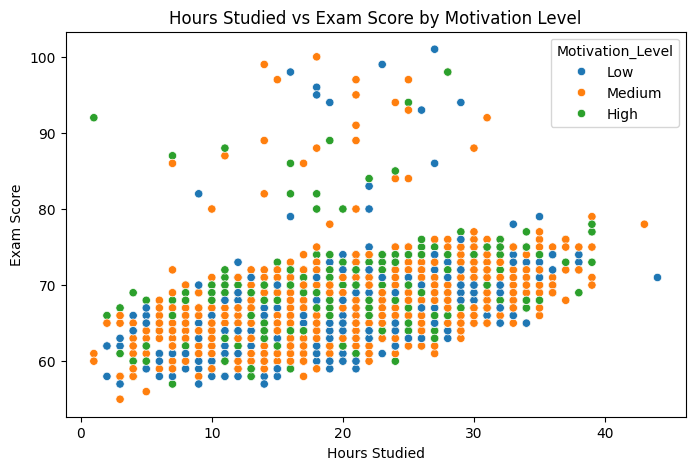

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Hours_Studied",
    y="Exam_Score",
    hue="Motivation_Level"
)

plt.title("Hours Studied vs Exam Score by Motivation Level")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")

plt.show()

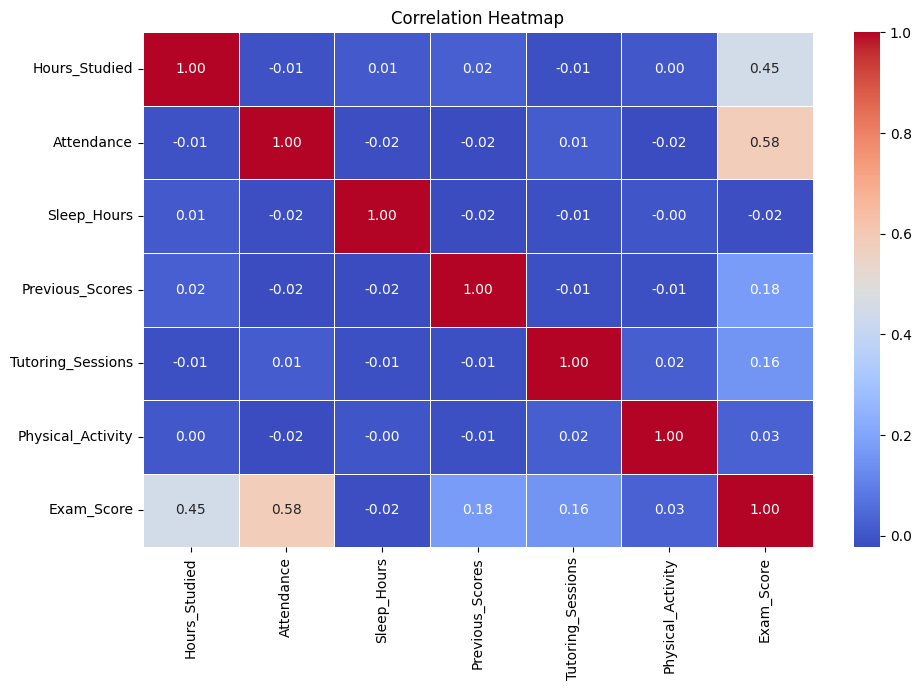

In [10]:
correlation = df[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

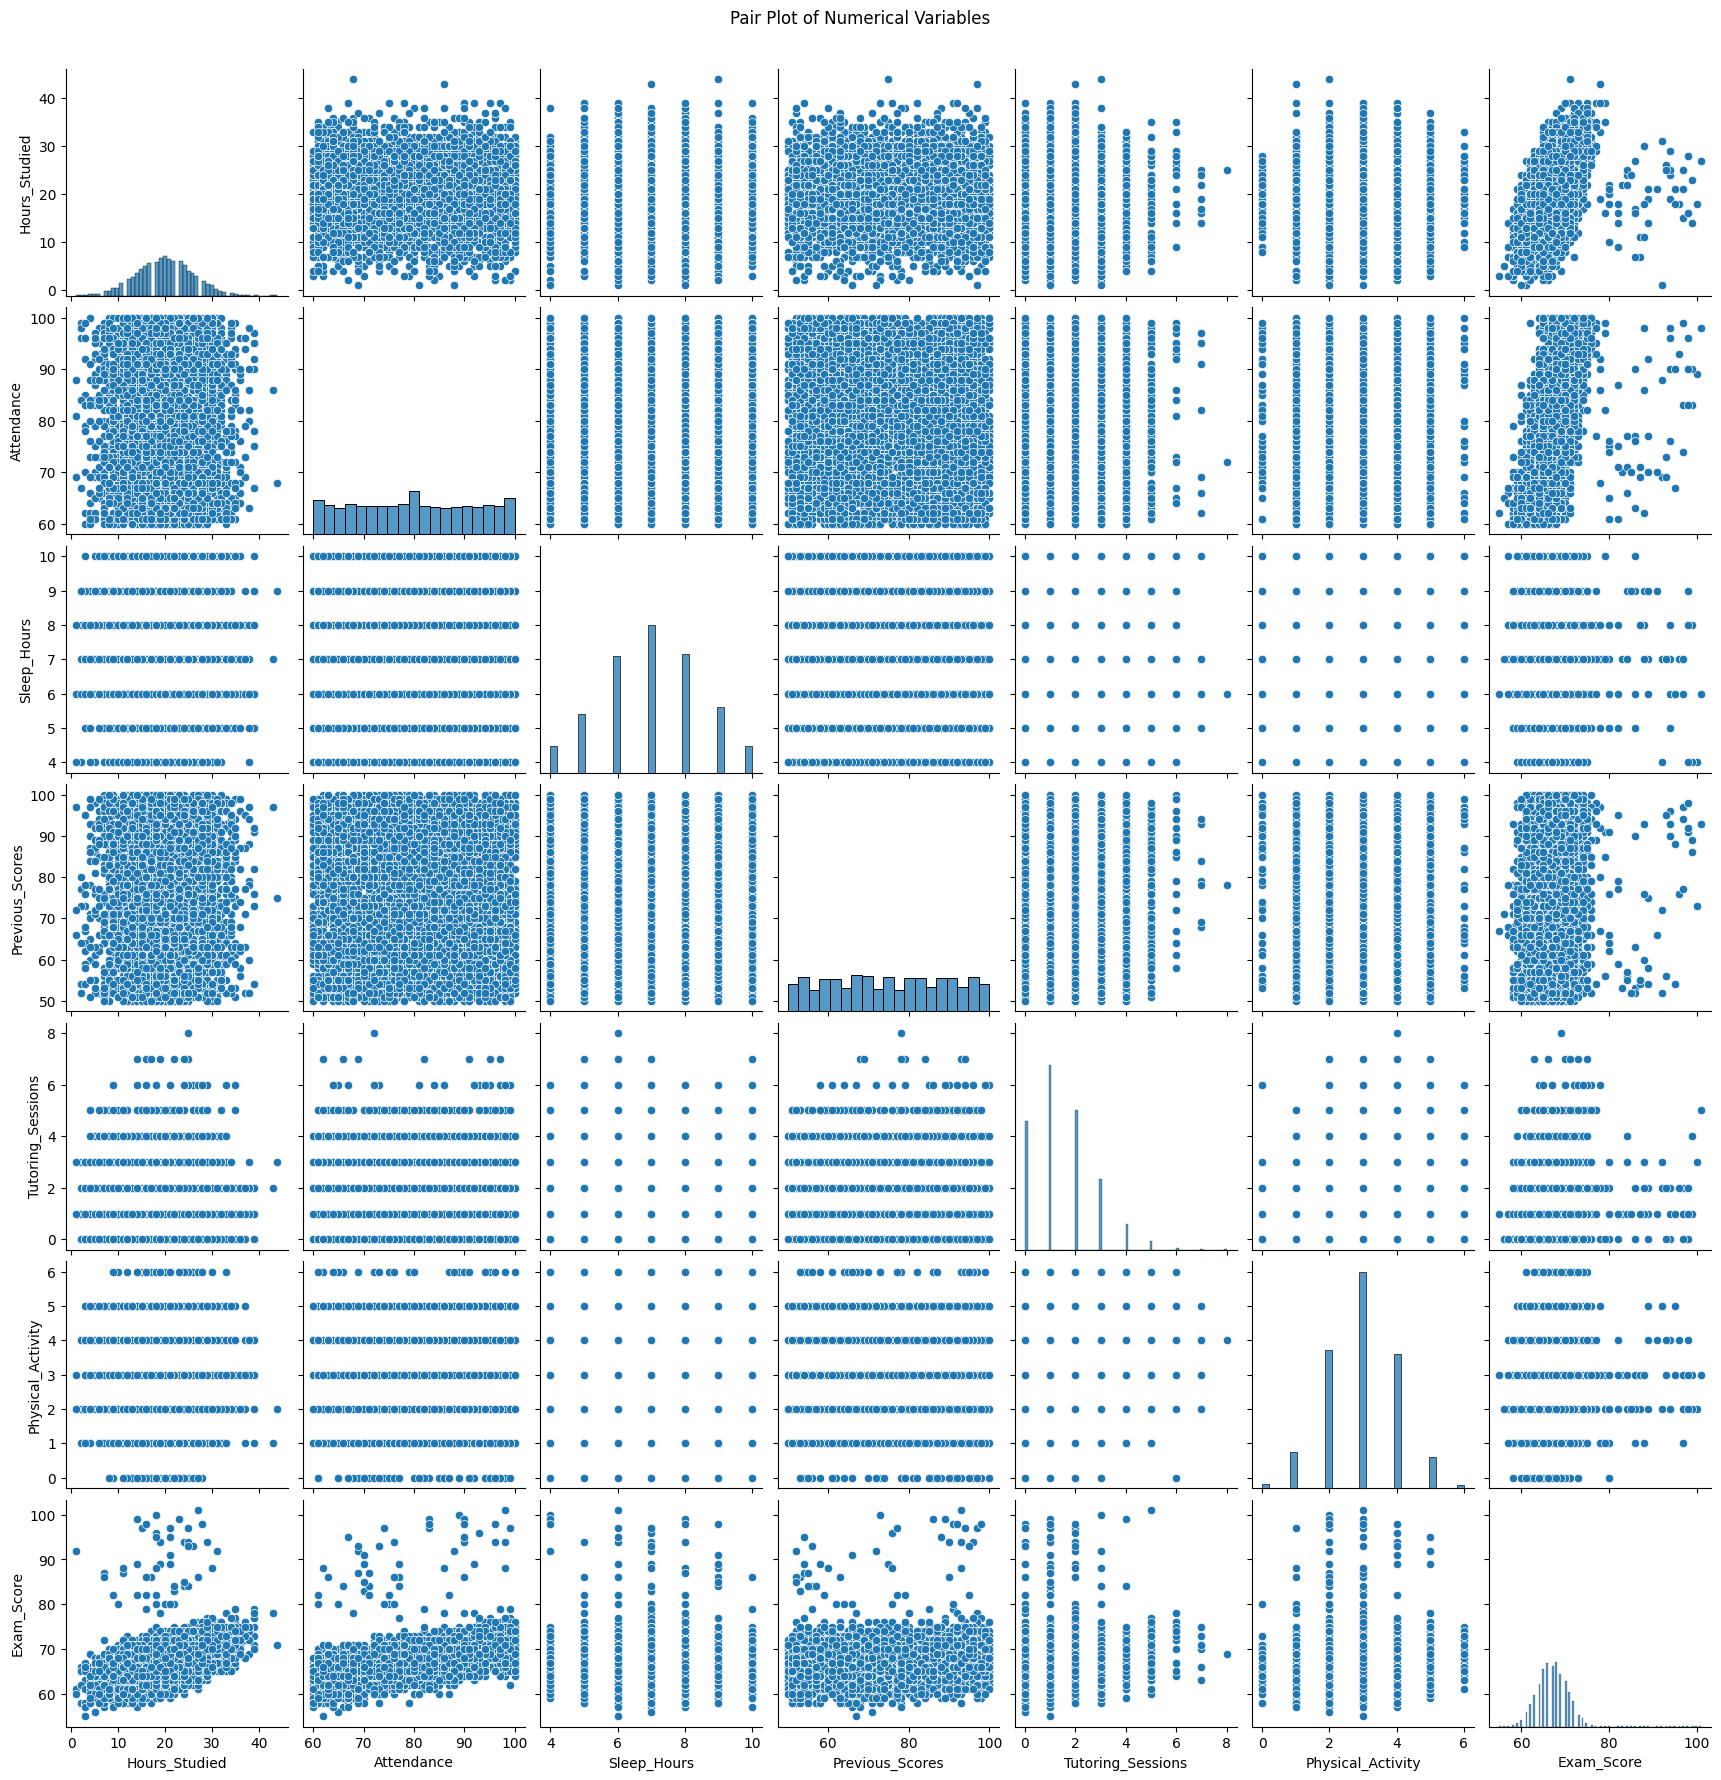

In [11]:
sns.pairplot(
    df[numeric_cols],
    diag_kind="hist"
)

plt.suptitle(
    "Pair Plot of Numerical Variables",
    y=1.02
)

plt.show()

In [12]:
from sklearn.linear_model import LinearRegression

In [13]:
df_reg = df[["Hours_Studied", "Exam_Score"]].dropna()

X = df_reg[["Hours_Studied"]]
y = df_reg["Exam_Score"]

print(X.head())
print(y.head())

   Hours_Studied
0             23
1             19
2             24
3             29
4             19
0    67
1    61
2    74
3    71
4    70
Name: Exam_Score, dtype: int64


In [14]:
model = LinearRegression()

model.fit(X, y)

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

print("Regression Equation:")
print(
    "Exam_Score =",
    model.intercept_,
    "+",
    model.coef_[0],
    "* Hours_Studied"
)

Coefficient: 0.28929062860958044
Intercept: 61.45698360950408
Regression Equation:
Exam_Score = 61.45698360950408 + 0.28929062860958044 * Hours_Studied


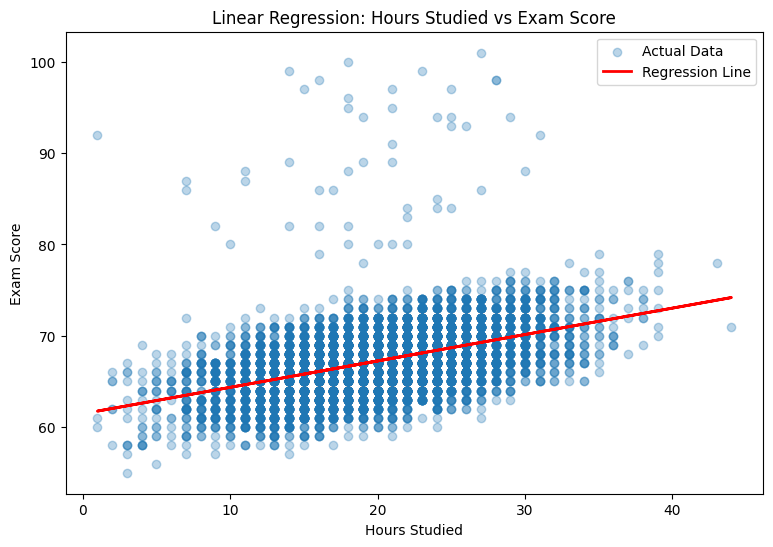

In [15]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X["Hours_Studied"],
    y,
    alpha=0.3,
    label="Actual Data"
)

plt.plot(
    X["Hours_Studied"],
    model.predict(X),
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Linear Regression: Hours Studied vs Exam Score")
plt.legend()
plt.show()